# 01. Análise descritiva: inadimplência e desastres naturais

Este caderno apresenta a cobertura dos dados, a distribuição dos registros de desastres e o comportamento da inadimplência de pessoas físicas entre janeiro de 2013 e dezembro de 2024. As tabelas utilizadas foram obtidas na preparação das bases do SCR/Banco Central e do Atlas Digital de Desastres no Brasil e estão disponíveis em `outputs/tables/`.

São 27 unidades da federação observadas em 144 meses (3.888 combinações UF-mês). O painel-base é construído pelos scripts em `src/`, mas as descritivas aqui podem ser consultadas diretamente a partir das saídas publicadas.

**Unidades de medida:** a inadimplência representa a participação percentual do saldo de carteira inadimplente na carteira ativa de pessoas físicas. Os desastres são **registros administrativos municipais**, e não eventos físicos únicos. A distribuição descritiva não permite inferência causal.

## 1. Bibliotecas e arquivos utilizados

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def raiz_projeto():
    for pasta in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        if (pasta / "outputs" / "tables").exists() and (pasta / "src").exists():
            return pasta
    raise FileNotFoundError("Abra o notebook a partir da pasta do projeto.")

ROOT = raiz_projeto()
TAB = ROOT / "outputs" / "tables"
def ler(nome, sep=";"):
    return pd.read_csv(TAB / nome, sep=sep, encoding="utf-8-sig")

plt.rcParams.update({"figure.figsize": (11, 4.3), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .22,
                     "font.size": 10})
AZUL, TURQUESA = "#254c68", "#16858c"
print("Tabelas:", TAB)

Tabelas: /workspace/scratch/14b3a63d85c1/tcc_repo/outputs/tables


## 2. Conferência das medidas e da cobertura

In [2]:
mensal = ler("segunda_etapa/series_nacionais_agregadas.csv", sep=",")
mensal["data"] = pd.to_datetime(mensal["data"])
mensal = mensal.sort_values("data").set_index("data").asfreq("MS")
por_tipo = ler("desastres_por_tipologia_2013_2024.csv")
por_grupo = ler("desastres_por_grupo_2013_2024.csv")
por_uf = ler("ranking_desastres_uf_2013_2024.csv")
taxa_uf = ler("ranking_inadimplencia_uf_2013_2024.csv")
uf_ano = ler("tabela_uf_ano_2013_2024.csv")
regiao_ano = ler("tabela_regiao_ano_2013_2024.csv")

total_registros = int(mensal["Total nacional"].sum())
total_climatico = int(mensal["Clima | Protocolos"].sum())
assert len(mensal) == 144
assert uf_ano["uf"].nunique() == 27
assert uf_ano.groupby("uf")["ano"].nunique().eq(12).all()
assert por_tipo["quantidade"].sum() == total_registros
assert por_grupo["quantidade"].sum() == total_registros
assert total_registros == 40339 and total_climatico == 37643

print("Período:", mensal.index.min().date(), "a", mensal.index.max().date())
print("Painel-base: 27 UFs x 144 meses = 3.888 observações")
print("Registros operacionais:", f"{total_registros:,}".replace(",", "."))
print("Subconjunto climático:", f"{total_climatico:,}".replace(",", "."))
display(mensal[["I", "Total nacional", "Clima | Protocolos"]].describe().round(2))

Período: 2013-01-01 a 2024-12-01
Painel-base: 27 UFs x 144 meses = 3.888 observações
Registros operacionais: 40.339
Subconjunto climático: 37.643


,I,Total nacional,Clima | Protocolos
count,144.00,144.00,144.00
mean,3.84,280.13,261.41
std,0.46,188.76,181.86
min,2.85,48.00,45.00
25%,3.60,157.50,141.75
50%,3.84,235.00,219.50
75%,4.14,357.25,334.25
max,5.03,1408.00,1348.00


A inadimplência nacional é a razão entre a soma dos saldos inadimplentes e a soma da carteira ativa, multiplicada por 100. A média simples das taxas estaduais não produziria a mesma medida. O critério do SCR.data corresponde a operações com pelo menos uma parcela vencida há **mais de 90 dias**; a taxa é medida pelo saldo da carteira correspondente.

As 16 tipologias da classificação operacional totalizam 40.339 protocolos. A seleção climática delimitada por códigos COBRADE soma 37.643 registros. As duas contagens usam recortes diferentes; somar os grupos às tipologias duplicaria as observações.

## 3. Evolução mensal das duas séries nacionais

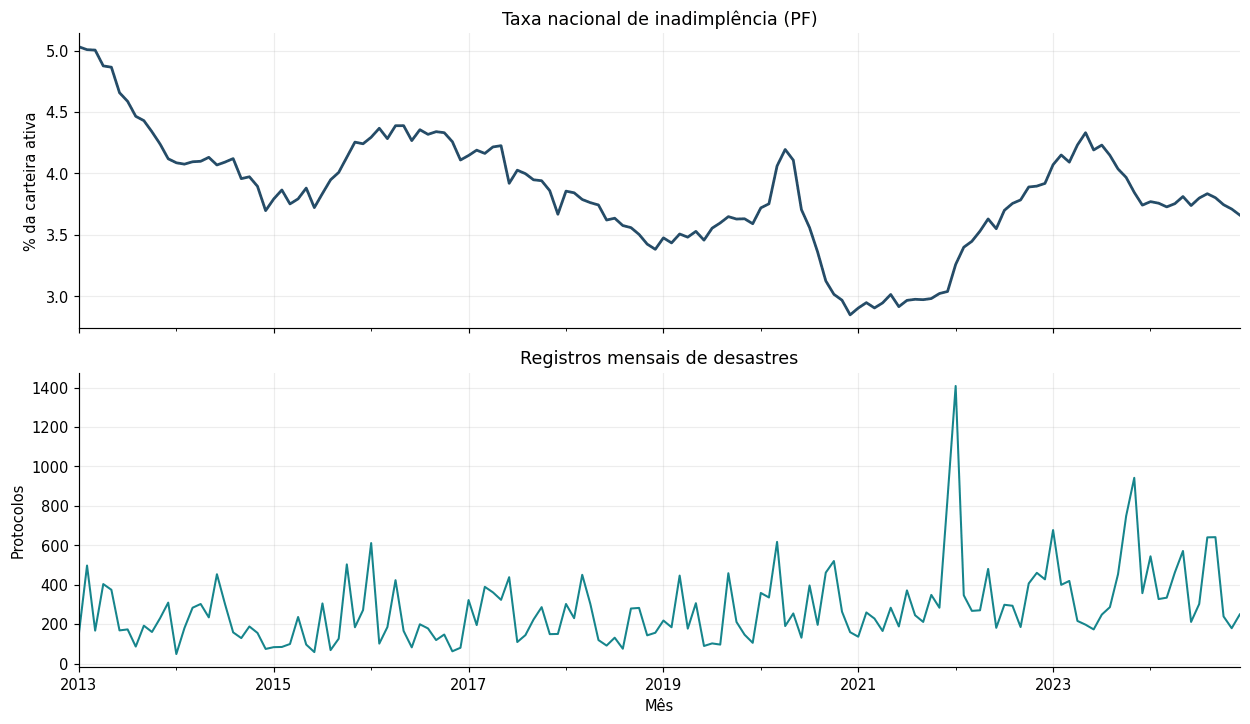

,inadimplencia_media,registros,registros_climaticos
ano,,,
2013,4.64,2911,2746
2014,4.02,2505,2434
2015,3.94,2113,2043
2016,4.31,2352,2197
2017,4.03,3089,2860
2018,3.64,2560,2286
2019,3.54,2538,2276
2020,3.53,3880,3695
2021,2.97,3556,3256


In [3]:
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
mensal["I"].plot(ax=ax[0], color=AZUL, lw=1.9)
ax[0].set(title="Taxa nacional de inadimplência (PF)", ylabel="% da carteira ativa", xlabel="")
mensal["Total nacional"].plot(ax=ax[1], color=TURQUESA, lw=1.4)
ax[1].set(title="Registros mensais de desastres", ylabel="Protocolos", xlabel="Mês")
fig.tight_layout()
plt.show()

anual = mensal.assign(ano=mensal.index.year).groupby("ano").agg(
    inadimplencia_media=("I", "mean"),
    registros=("Total nacional", "sum"),
    registros_climaticos=("Clima | Protocolos", "sum"),
)
display(anual.round(2))

As séries têm escalas e dinâmicas distintas. Mesmo que existam meses ou anos com maior ocorrência de registros, a coincidência visual com a inadimplência não determina direção de associação. A decomposição temporal e os testes de estacionariedade são tratados no próximo notebook.

## 4. Frequência por grupo e tipologia

,grupo_de_desastre,quantidade,percentual
0,Climatológico,19518,48.4
1,Hidrológico,15409,38.2
2,Meteorológico,3716,9.2
3,Outros,1696,4.2


,descricao_tipologia,quantidade,percentual
0,Estiagem e Seca,16149,40.0
1,Chuvas Intensas,8084,20.0
2,Incêndio Florestal,3081,7.6
3,Enxurradas,2759,6.8
4,Vendavais e Ciclones,2553,6.3
5,Inundações,2065,5.1
6,Alagamentos,1504,3.7
7,Movimento de Massa,1103,2.7
8,Granizo,1070,2.7
9,Outros,836,2.1


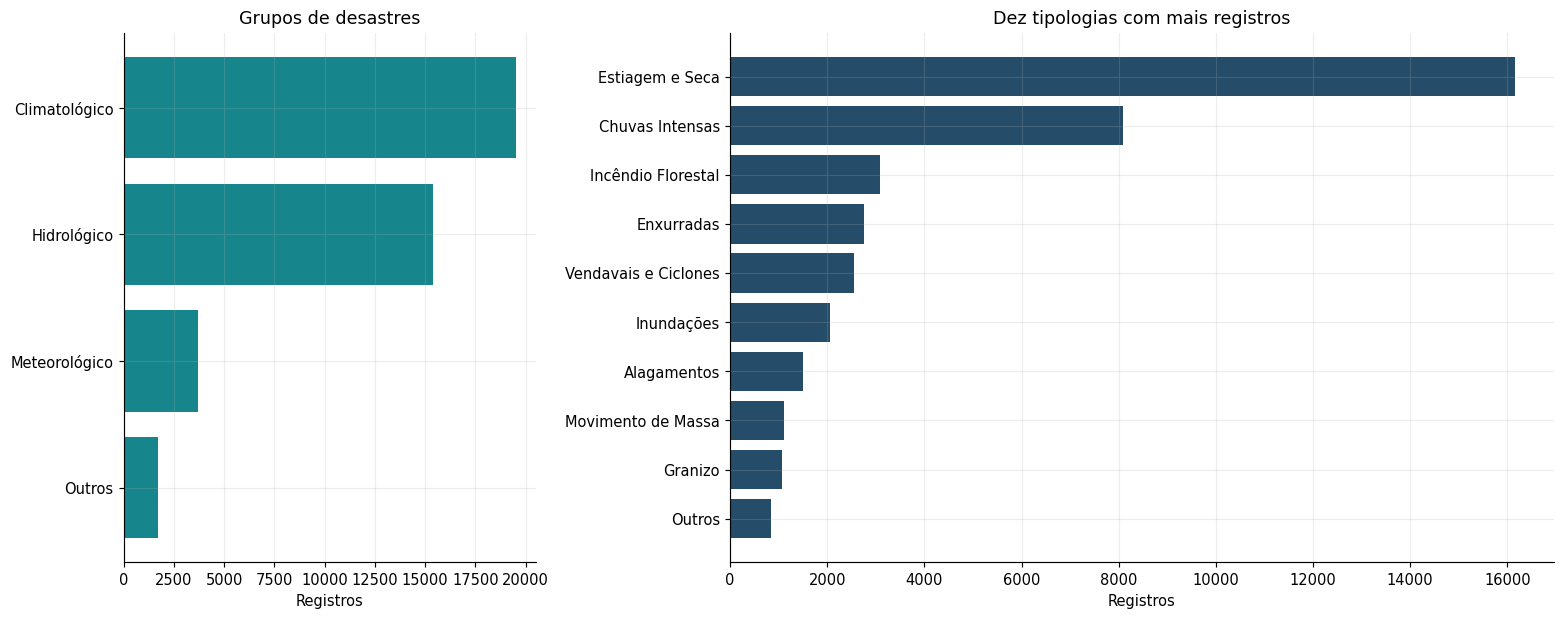

In [4]:
display(por_grupo.assign(percentual=100*por_grupo["quantidade"]/total_registros).round(1))
display(por_tipo.assign(percentual=100*por_tipo["quantidade"]/total_registros).round(1))

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1, 2]})
g = por_grupo.sort_values("quantidade")
axes[0].barh(g["grupo_de_desastre"], g["quantidade"], color=TURQUESA)
axes[0].set(title="Grupos de desastres", xlabel="Registros")
t = por_tipo.sort_values("quantidade").tail(10)
axes[1].barh(t["descricao_tipologia"], t["quantidade"], color=AZUL)
axes[1].set(title="Dez tipologias com mais registros", xlabel="Registros")
fig.tight_layout()
plt.show()

Estiagem e seca, chuvas intensas e incêndio florestal somam cerca de **67,7% dos registros**. Essa participação informa a frequência administrativa das tipologias, não o tamanho dos prejuízos econômicos nem a intensidade física de cada evento.

## 5. Distribuição regional e estadual

,regiao,total_desastres,percentual
2,Norte,3605,8.9
0,Centro-Oeste,3849,9.5
3,Sudeste,8403,20.8
4,Sul,10615,26.3
1,Nordeste,13867,34.4


,uf,regiao,total_desastres
0,MG,Sudeste,4955
1,SC,Sul,4761
2,RS,Sul,4740
3,BA,Nordeste,3376
4,PB,Nordeste,2244
5,PE,Nordeste,1943
6,MS,Centro-Oeste,1797
7,RN,Nordeste,1749
8,MT,Centro-Oeste,1631
9,PA,Norte,1580


,uf,regiao,taxa_media_inadimplencia
0,RJ,Sudeste,5.667
1,AM,Norte,5.289
2,PE,Nordeste,5.219
3,AL,Nordeste,5.063
4,AP,Norte,4.928
5,BA,Nordeste,4.817
6,RN,Nordeste,4.722
7,PA,Norte,4.685
8,CE,Nordeste,4.669
9,RR,Norte,4.526


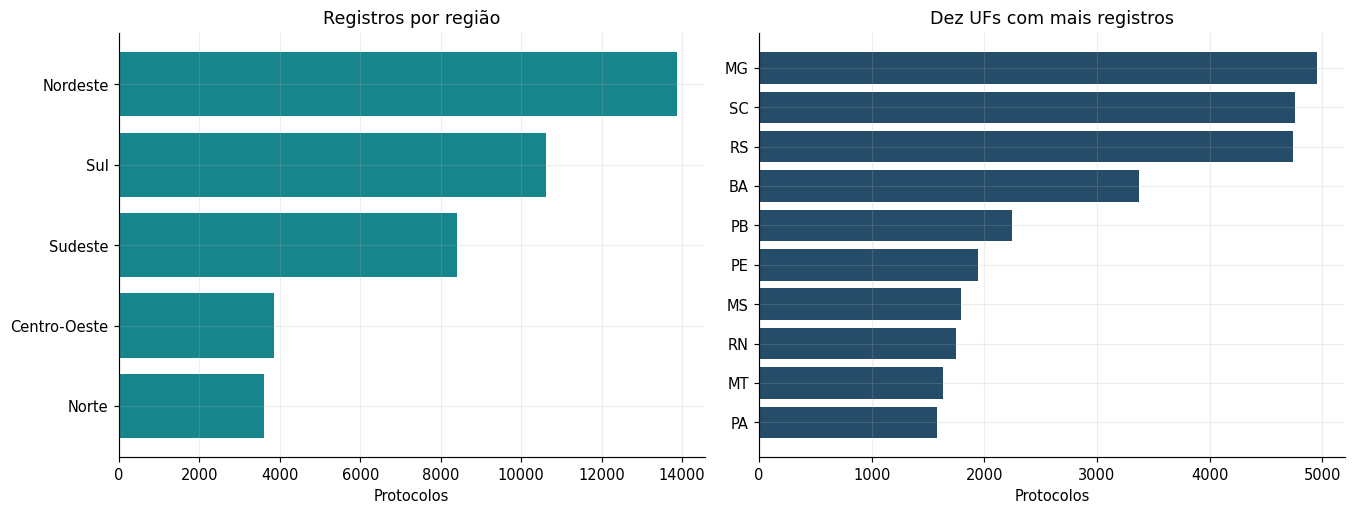

In [5]:
reg = regiao_ano.groupby("regiao", as_index=False)["total_desastres"].sum().sort_values("total_desastres")
reg["percentual"] = 100 * reg["total_desastres"] / total_registros
display(reg.round(1))
display(por_uf.head(12))
display(taxa_uf.head(12).round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].barh(reg["regiao"], reg["total_desastres"], color=TURQUESA)
axes[0].set(title="Registros por região", xlabel="Protocolos")
top = por_uf.head(10).iloc[::-1]
axes[1].barh(top["uf"], top["total_desastres"], color=AZUL)
axes[1].set(title="Dez UFs com mais registros", xlabel="Protocolos")
fig.tight_layout()
plt.show()

## 6. Evolução da inadimplência por região e por UF

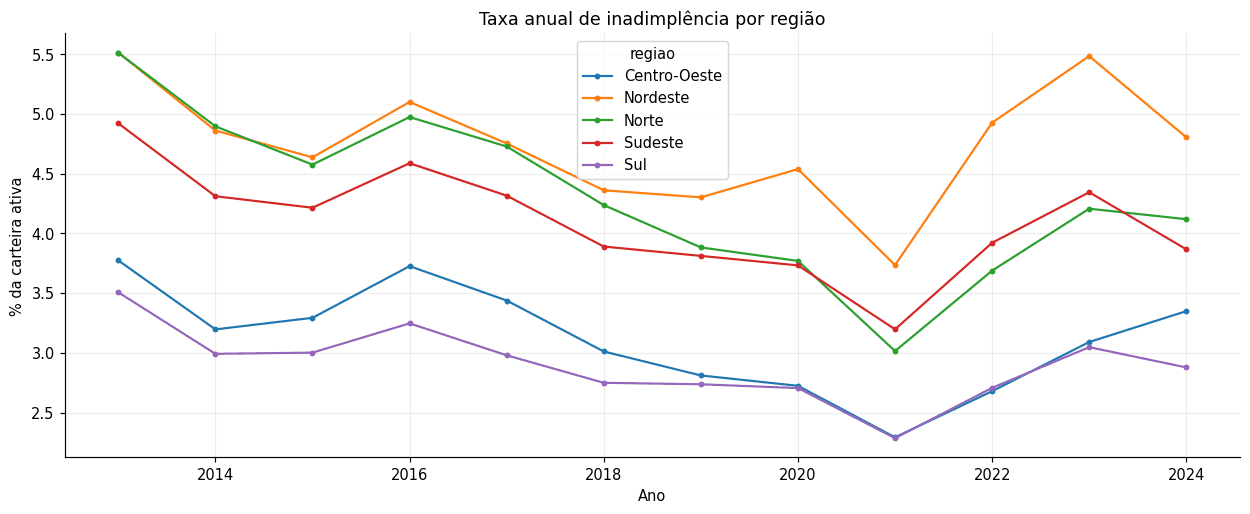

,uf,regiao,taxa_media_inadimplencia
0,RJ,Sudeste,5.667
1,AM,Norte,5.289
2,PE,Nordeste,5.219
3,AL,Nordeste,5.063
4,AP,Norte,4.928
5,BA,Nordeste,4.817
6,RN,Nordeste,4.722
7,PA,Norte,4.685
8,CE,Nordeste,4.669
9,RR,Norte,4.526


In [6]:
# Nas taxas anuais, a agregação correta é a razão entre saldos.
regiao_ano = regiao_ano.copy()
regiao_ano["taxa_recalculada"] = 100 * regiao_ano["carteira_inadimplencia"] / regiao_ano["carteira_ativa"]
assert np.allclose(regiao_ano["taxa_inadimplencia"], regiao_ano["taxa_recalculada"])
pivot = regiao_ano.pivot(index="ano", columns="regiao", values="taxa_inadimplencia")
ax = pivot.plot(figsize=(12, 5), marker="o", ms=3, lw=1.5)
ax.set(title="Taxa anual de inadimplência por região", ylabel="% da carteira ativa", xlabel="Ano")
plt.tight_layout()
plt.show()

display(taxa_uf.sort_values("taxa_media_inadimplencia", ascending=False).head(10).round(3))

Os rankings estaduais de registros e inadimplência não são diretamente comparáveis como estimativas de impacto. Tanto a estrutura econômica quanto a composição das carteiras e os padrões de notificação diferem entre as UFs.

## 7. Sazonalidade e diferenças entre meses

I        Total nacional       
      mean median           mean median
data                                   
1     3.87   3.82         404.92  312.0
2     3.90   3.85         261.42  244.5
3     3.90   3.92         323.67  308.5
4     3.94   3.95         292.25  286.0
5     3.97   3.99         283.50  268.5
6     3.82   3.73         188.58  170.5
7     3.86   3.82         244.58  273.0
8     3.84   3.89         205.42  168.0
9     3.80   3.88         289.75  217.0
10    3.79   3.92         336.50  284.0
11    3.75   3.85         266.33  181.5
12    3.67   3.68         264.67  204.0

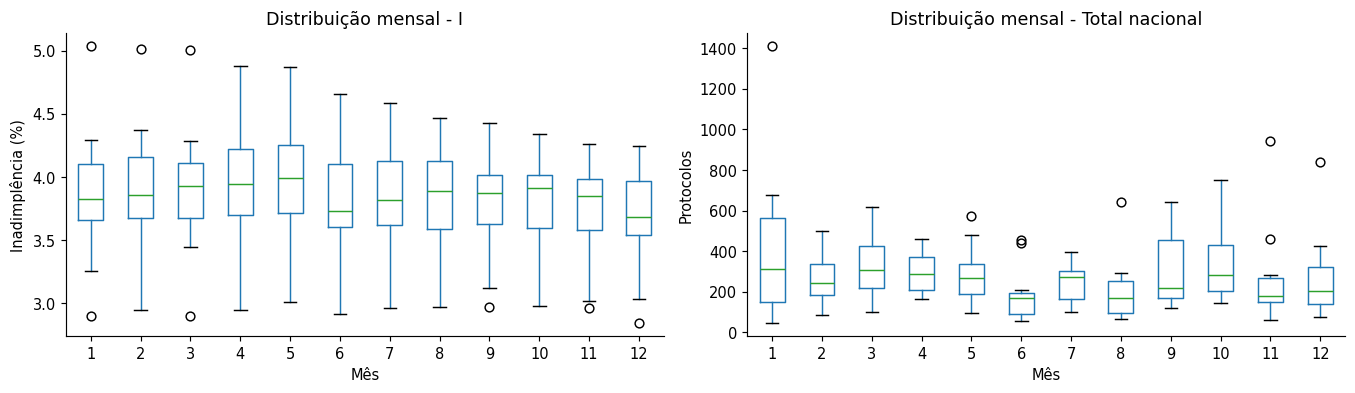

In [7]:
perfil = mensal.groupby(mensal.index.month)[["I", "Total nacional"]].agg(["mean", "median"])
display(perfil.round(2))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for col, ax, ylabel in [("I", axes[0], "Inadimplência (%)"), ("Total nacional", axes[1], "Protocolos")]:
    mensal.assign(mes=mensal.index.month).boxplot(column=col, by="mes", ax=ax, grid=False)
    ax.set(title="Distribuição mensal - " + col, xlabel="Mês", ylabel=ylabel)
fig.suptitle("")
plt.tight_layout()
plt.show()

## 8. Leitura conjunta sem interpretação causal

In [8]:
recortes = {
    "pré-pandemia": mensal.loc[:"2020-01-01"],
    "período completo": mensal,
}
resumo = []
for nome, parte in recortes.items():
    resumo.append({"recorte": nome, "meses": len(parte),
                   "taxa_média_%": parte["I"].mean(),
                   "registros": parte["Total nacional"].sum(),
                   "meses_sem_registro": (parte["Total nacional"] == 0).sum()})
display(pd.DataFrame(resumo).round(2))

,recorte,meses,taxa_média_%,registros,meses_sem_registro
0,pré-pandemia,85,4.01,18426,0
1,período completo,144,3.84,40339,0


**Síntese.** O estudo utiliza um painel mensal balanceado de 27 UFs entre 2013 e 2024. A distribuição dos registros é concentrada em algumas tipologias e regiões, e a taxa de inadimplência apresenta diferenças entre estados e ao longo do tempo. As associações condicionais são investigadas nos notebooks de Granger, DLM e SARIMAX.